# Regression Models: Polynomial Fitting, Logistic Regression by Gradient Descent, and Regularisation
Three implementations on one theme, from model capacity to optimisation to regularisation:
  A. Polynomial regression (degrees 1-3) on synthetic linear data with Gaussian noise
  B. Logistic regression trained with hand-written batch gradient descent (two learning rates)
  C. Ordinary least squares vs LASSO vs ridge on a 10-feature dataset

Run from this folder:  python regression_models.py   (figures are written to ./figures)

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else "."
DATA = os.path.join(HERE, "data")
FIG = os.path.join(HERE, "figures")
os.makedirs(FIG, exist_ok=True)

BLUE, ORANGE, GREEN, PURPLE, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd1", "#6b6b6b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

## A. Polynomial regression on noisy linear data

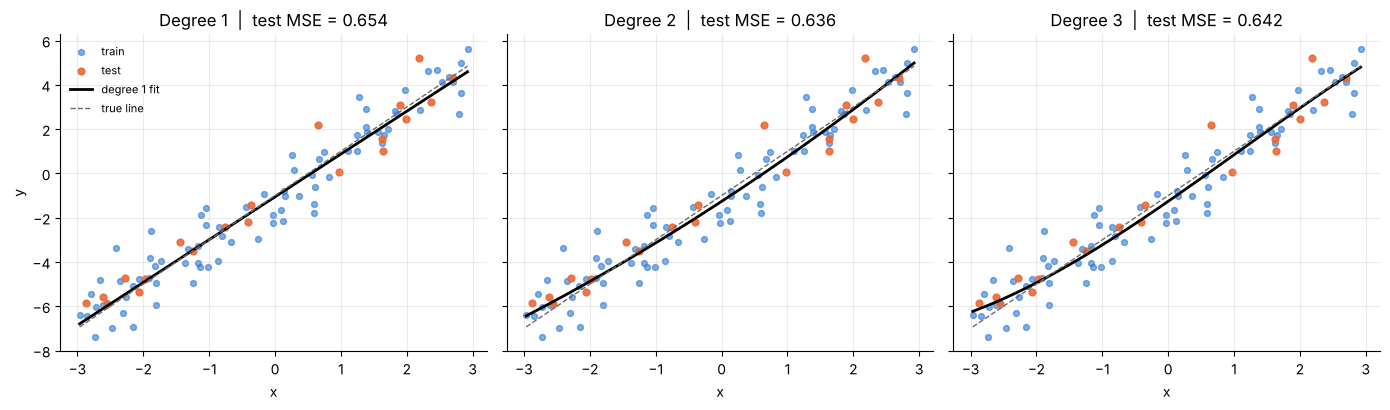

Polynomial regression (train / test MSE):
  degree 1: train 0.8477 | test 0.6537 | intercept -1.058 | coefs [1.933]
  degree 2: train 0.8147 | test 0.6358 | intercept -1.264 | coefs [1.943 0.067]
  degree 3: train 0.8075 | test 0.6420 | intercept -1.263 | coefs [ 2.056  0.067 -0.021]


In [2]:
rng = np.random.seed(42)
N = 100
X = np.random.uniform(-3, 3, N).reshape(-1, 1)
y = 2 * X.ravel() - 1 + np.random.normal(0, 1, N)          # true model: y = 2x - 1 + eps, eps ~ N(0, 1)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

poly_results = {}
x_grid = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, deg in zip(axes, [1, 2, 3]):
    model = make_pipeline(PolynomialFeatures(deg), LinearRegression()).fit(X_tr, y_tr)
    mse_tr = mean_squared_error(y_tr, model.predict(X_tr))
    mse_te = mean_squared_error(y_te, model.predict(X_te))
    coefs = model.named_steps["linearregression"]
    poly_results[deg] = dict(train_mse=mse_tr, test_mse=mse_te,
                             intercept=coefs.intercept_, coef=coefs.coef_[1:])
    ax.scatter(X_tr, y_tr, s=18, color=BLUE, alpha=0.6, label="train")
    ax.scatter(X_te, y_te, s=24, color=ORANGE, alpha=0.9, label="test")
    ax.plot(x_grid, model.predict(x_grid), color="black", lw=2, label=f"degree {deg} fit")
    ax.plot(x_grid, 2 * x_grid - 1, color=GREY, lw=1, ls="--", label="true line")
    ax.set_title(f"Degree {deg}  |  test MSE = {mse_te:.3f}")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "polynomial_fits.png"), dpi=160)
plt.show()

print("Polynomial regression (train / test MSE):")
for d, r in poly_results.items():
    print(f"  degree {d}: train {r['train_mse']:.4f} | test {r['test_mse']:.4f} | "
          f"intercept {r['intercept']:.3f} | coefs {np.round(r['coef'], 3)}")

## B. Logistic regression with batch gradient descent
Optimised with the cross-entropy gradient; the mean squared error between the predicted probability
and the label is tracked at every iteration, together with cross-entropy and accuracy.

lr=0.01: final weights [b, w1, w2] = [-0.04688  0.02108 -0.01723] | MSE 0.24266 | acc 0.745
lr=0.05: final weights [b, w1, w2] = [-0.21359  0.10199 -0.08563] | MSE 0.21854 | acc 0.745
lr=0.05, 3000 iterations: weights [-1.7651  3.5104 -3.4101] | MSE 0.0881 | acc 0.880
majority-class accuracy: 0.740


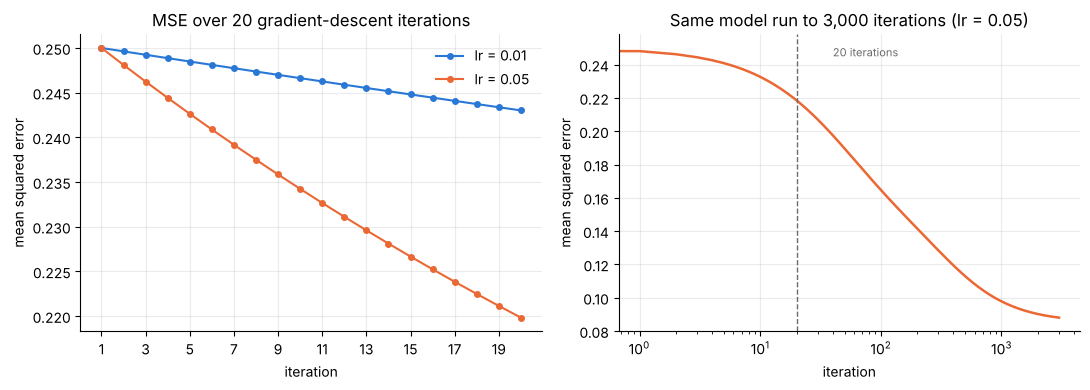

In [3]:
df = pd.read_csv(os.path.join(DATA, "logistic_data.csv"))
# 'Samples' is only a row index, so it is excluded from the features
Xl = df[["Feature 1", "Feature 2"]].values
yl = df["Output"].values.astype(float)
Xl = StandardScaler().fit_transform(Xl)          # Feature 2 is in the tens of thousands
Xl = np.c_[np.ones(len(Xl)), Xl]                 # bias column


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -250, 250)))


def logistic_gd(X, y, lr, n_iter=20):
    w = np.zeros(X.shape[1])
    hist = {"mse": [], "bce": [], "acc": []}
    for _ in range(n_iter):
        p = sigmoid(X @ w)
        pc = np.clip(p, 1e-15, 1 - 1e-15)
        hist["mse"].append(np.mean((p - y) ** 2))
        hist["bce"].append(-np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc)))
        hist["acc"].append(np.mean((p >= 0.5) == y))
        w -= lr * X.T @ (p - y) / len(y)         # gradient of the mean cross-entropy
    p = sigmoid(X @ w)
    return w, hist, np.mean((p - y) ** 2), np.mean((p >= 0.5) == y)


logit = {}
for lr in [0.01, 0.05]:
    w, hist, mse_final, acc_final = logistic_gd(Xl, yl, lr, n_iter=20)
    logit[lr] = dict(w=w, hist=hist, mse=mse_final, acc=acc_final)
    print(f"lr={lr}: final weights [b, w1, w2] = {np.round(w, 5)} | MSE {mse_final:.5f} | acc {acc_final:.3f}")

# longer run (not part of the 20-iteration setting) to show where gradient descent is heading
w_long, hist_long, mse_long, acc_long = logistic_gd(Xl, yl, 0.05, n_iter=3000)
print(f"lr=0.05, 3000 iterations: weights {np.round(w_long, 4)} | MSE {mse_long:.4f} | acc {acc_long:.3f}")
base_rate = 1 - yl.mean()
print(f"majority-class accuracy: {base_rate:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
it = np.arange(1, 21)
for lr, col in [(0.01, BLUE), (0.05, ORANGE)]:
    axes[0].plot(it, logit[lr]["hist"]["mse"], "o-", ms=4, color=col, label=f"lr = {lr}")
axes[0].set(xlabel="iteration", ylabel="mean squared error", title="MSE over 20 gradient-descent iterations")
axes[0].set_xticks(range(1, 21, 2))
axes[0].legend(frameon=False)
axes[1].plot(hist_long["mse"], color=ORANGE, lw=1.8)
axes[1].axvline(20, color=GREY, ls="--", lw=1)
axes[1].text(40, max(hist_long["mse"]) * 0.98, "20 iterations", color=GREY, fontsize=8)
axes[1].set(xlabel="iteration", ylabel="mean squared error", title="Same model run to 3,000 iterations (lr = 0.05)")
axes[1].set_xscale("log")
plt.tight_layout()
plt.savefig(os.path.join(FIG, "logistic_gd_mse.png"), dpi=160)
plt.show()

## C. Linear regression vs LASSO vs ridge
The course defines the regularised error as  E = sum (r - g)^2 + lambda * penalty.
With lambda/2 = 1 (LASSO) and lambda/2 = 0.1 (ridge) this maps onto scikit-learn as
  Ridge:  RSS + alpha ||w||^2            ->  alpha = lambda       = 0.2
  Lasso:  RSS/(2n) + alpha ||w||_1        ->  alpha = lambda/(2n)  = 1/n
All three models are fitted on the same standardised features so their coefficients are comparable.

Linear (OLS)             test MSE 4.7221 | non-zero coefs 10/10
   coefs: [ 4.398 -3.283  2.066  0.119 -0.259  0.031 -0.497  1.035 -1.809  3.981]
LASSO (λ/2 = 1)          test MSE 4.6396 | non-zero coefs 10/10
   coefs: [ 4.385 -3.27   2.056  0.1   -0.247  0.028 -0.474  1.018 -1.788  3.974]
Ridge (λ/2 = 0.1)        test MSE 4.6896 | non-zero coefs 10/10
   coefs: [ 4.386 -3.275  2.062  0.119 -0.258  0.034 -0.492  1.033 -1.802  3.973]
LASSO, strong (α = 2)    test MSE 21.7873 | non-zero coefs 4/10
   coefs: [ 2.326 -1.14   0.078  0.    -0.     0.     0.     0.    -0.     2.715]


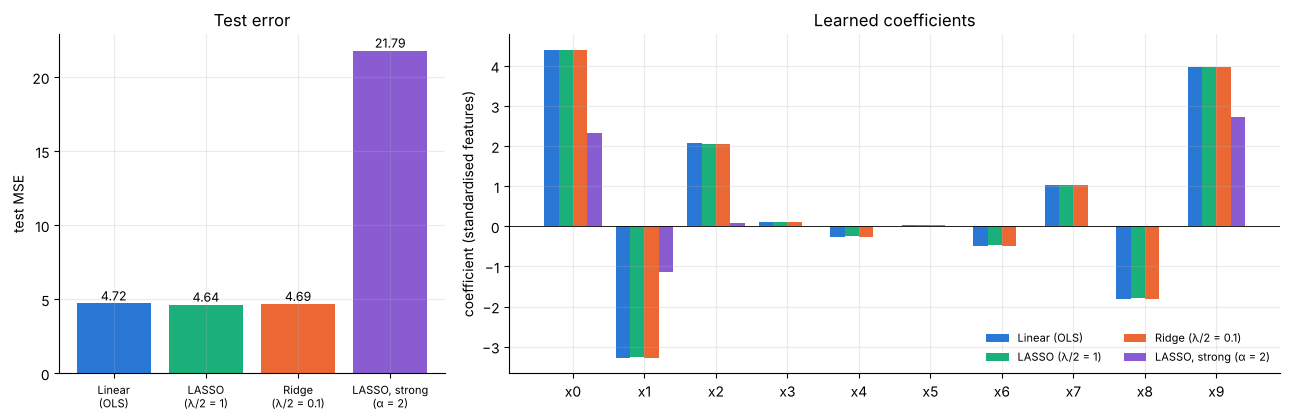

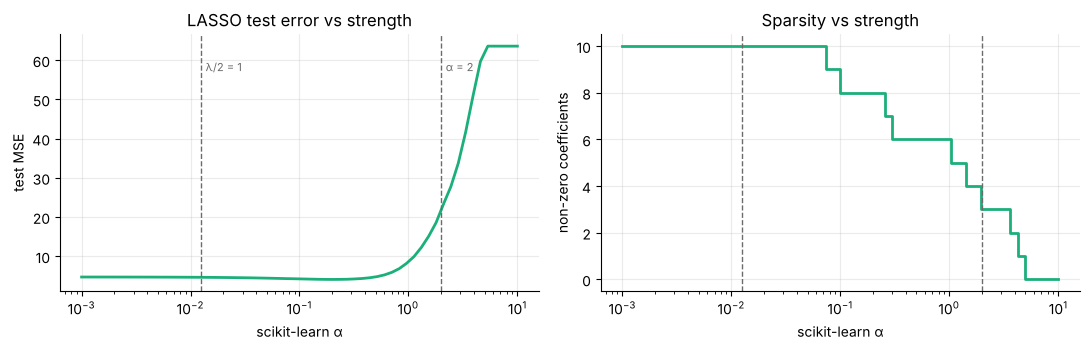

In [4]:
dr = pd.read_csv(os.path.join(DATA, "regularisation_data.csv"))
Xr, yr = dr.iloc[:, :-1].values, dr.iloc[:, -1].values
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42)
sc = StandardScaler().fit(Xr_tr)
Xr_tr, Xr_te = sc.transform(Xr_tr), sc.transform(Xr_te)
n_tr = len(yr_tr)

reg_models = {
    "Linear (OLS)": LinearRegression(),
    "LASSO (λ/2 = 1)": Lasso(alpha=2.0 / (2 * n_tr), max_iter=100000),
    "Ridge (λ/2 = 0.1)": Ridge(alpha=0.2),
    "LASSO, strong (α = 2)": Lasso(alpha=2.0, max_iter=100000),   # setting used in the first run, for comparison
}
reg_res = {}
for name, m in reg_models.items():
    m.fit(Xr_tr, yr_tr)
    reg_res[name] = dict(mse=mean_squared_error(yr_te, m.predict(Xr_te)), coef=m.coef_.copy(),
                         nonzero=int(np.sum(np.abs(m.coef_) > 1e-8)))
    print(f"{name:<24} test MSE {reg_res[name]['mse']:.4f} | non-zero coefs {reg_res[name]['nonzero']}/10")
    print("   coefs:", np.round(m.coef_, 3))

names = list(reg_res)
cols = [BLUE, GREEN, ORANGE, PURPLE]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1, 2]})
bars = axes[0].bar(range(4), [reg_res[n]["mse"] for n in names], color=cols)
for b in bars:
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.2f}",
                 ha="center", va="bottom", fontsize=9)
axes[0].set_xticks(range(4))
axes[0].set_xticklabels([n.replace(" (", "\n(") for n in names], fontsize=8)
axes[0].set(ylabel="test MSE", title="Test error")
xs = np.arange(10)
wd = 0.2
for i, (n, c) in enumerate(zip(names, cols)):
    axes[1].bar(xs + (i - 1.5) * wd, reg_res[n]["coef"], wd, color=c, label=n)
axes[1].axhline(0, color="black", lw=0.6)
axes[1].set_xticks(xs)
axes[1].set_xticklabels([f"x{i}" for i in range(10)])
axes[1].set(ylabel="coefficient (standardised features)", title="Learned coefficients")
axes[1].legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "regularisation_comparison.png"), dpi=160)
plt.show()

# LASSO path: how many coefficients survive as alpha grows
alphas = np.logspace(-3, 1, 60)
path_mse, path_nz = [], []
for a in alphas:
    m = Lasso(alpha=a, max_iter=100000).fit(Xr_tr, yr_tr)
    path_mse.append(mean_squared_error(yr_te, m.predict(Xr_te)))
    path_nz.append(np.sum(np.abs(m.coef_) > 1e-8))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(alphas, path_mse, color=GREEN, lw=2)
ax[1].step(alphas, path_nz, color=GREEN, lw=2, where="mid")
for a_, lab in [(1 / n_tr, "λ/2 = 1"), (2.0, "α = 2")]:
    for k in range(2):
        ax[k].axvline(a_, color=GREY, ls="--", lw=1)
    ax[0].text(a_ * 1.1, max(path_mse) * 0.9, lab, fontsize=8, color=GREY)
ax[0].set(xscale="log", xlabel="scikit-learn α", ylabel="test MSE", title="LASSO test error vs strength")
ax[1].set(xscale="log", xlabel="scikit-learn α", ylabel="non-zero coefficients", title="Sparsity vs strength")
plt.tight_layout()
plt.savefig(os.path.join(FIG, "lasso_path.png"), dpi=160)
plt.show()